[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/dimarkov/jaxpruner/blob/main/jaxpruner/projects/bigsparse/sparsity-scaling.ipynb)

This notebook demonstrates how to fit a sparsity scaling law for a set of experiments with different model sizes, sparsity values and amounts of data used for training.

## Download data from Github

In [1]:
import sys
if 'google.colab' in sys.modules:
# No need to download them if running locally.
  !wget --no-cache --backups=1 https://raw.githubusercontent.com/google-research/jaxpruner/main/jaxpruner/projects/bigsparse/vit-data.json
  !wget --no-cache --backups=1 https://raw.githubusercontent.com/google-research/jaxpruner/main/jaxpruner/projects/bigsparse/t5-data.csv

## Imports and Plot Setup



In [2]:
from collections import defaultdict
import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy

plt.rcParams['lines.linewidth'] = 1.5 * plt.rcParamsDefault['lines.linewidth']
plt.rcParams['lines.markersize'] = 1.5 * plt.rcParamsDefault['lines.markersize']
plt.rcParams['font.size'] = 1.5 * plt.rcParamsDefault['font.size']

## Load ViT experiment data

In [3]:
data = pd.read_json('vit-data.json')

PARAM_COUNT = 12 * (12 * 768 ** 2)
S = data['sparsity'] # sparsity
N = PARAM_COUNT * data['scale'] * (1 - data['sparsity']) #nonzero params
N /= 10 ** 6 # normalize for numerical stability during fitting
D = data['total_examples'] # number of training examples
D /= 10 ** 9 # normalize for numerical stability during fitting
L = data['val-loss'] # target validation loss
# Normalization is important to make sure that all coefficients are in a
# reasonable (and somewhat similar) range during fitting as the optimizer may
# otherwise frequently diverge or simply fail to find a good solution.

x = np.stack((S, N, D))
y = np.array(L)

# Fit Scaling Coefficients

In [4]:
# Loss function that we optimize in order to find our scaling coefficients`.
def huber(f, x, y, delta, log):
  def res(params):
    if log:
      res = np.abs(np.log(f(x, params)) - np.log(y))
    else:
      res = np.abs(f(x, params) - y)
    outlier = res > delta
    loss = np.sum(delta * (res[outlier] - .5 * delta))
    loss += np.sum(.5 * res[~outlier] ** 2)
    return loss / y.size
  return res

# Our main scaling function that we want to find the coefficients `params` of.
# We note that we found fitting with negative exponents slightly more consistent
# and less prone to numerical issues.
def law(x, params):
  S, N, D = x[0], x[1], x[2]
  a, b, c, d, e, f, g = params
  sparse = a * (1 / (1 - S)) ** -b + c
  return sparse * N ** -d + e * D ** -f + g

# For ViTs we find that `delta=.01` and `log=False` yield the best fit; whereas
# for language models we follow the procedure in the Chinchilla paper with
# `delta=0.001` and `log=True`.
loss = lambda f, x, y: huber(f, x, y, 0.01, False)

# Fix seed to make runs repeatable
np.random.seed(0)

# Since the problem is not guaranteed to be convex, we optimize multiple times
# from random starting points. However, it seems that most of the time we find a
# very similar solution, especially when numerics are decently configured
# through normalization and the scaling law is written in its most favorable
# (equivalent) form (with negative exponents).
best = None
for _ in range(25):
  res = scipy.optimize.minimize(
      loss(law, x, y), np.random.uniform(size=7)
  )
  if res['success']:
    print(res['fun'])
    if best is None or best['fun'] > res['fun']:
      best = res
      print(best['fun'])

# Print scaling coefficients and corresponding fitting loss
print('coefs', best['x'])
print('loss', best['fun'])
params = best['x']

0.0004929090123134074
0.0004929090123134074
0.0004929088124953952
0.0004929088124953952
0.0004929088375235268
0.0004929089017817107
0.0004929088087651522
0.0004929088087651522
0.0004929087948005292
0.0004929087948005292
0.0004929088564507702
0.0004929089855446514
0.0004929088086291371
0.0004929088708336065
0.0004929093467103901
0.0004929114828210363


0.0004929089117782697
0.0004929091164446394
0.0004929088340180001
0.0004929101429445546
0.0004929088154700357
0.0004929089417787917
0.0004929088358770786
0.0004929089562038575
0.0004929093017133061
0.0004929095961961609
0.0004929097085635741


0.0004929090577288619
0.0004929092766010003
coefs [1.30485412 0.82097396 2.07508434 0.39221668 0.27818312 0.88977493
 4.51665292]
loss 0.0004929087948005292


# Plot Quality of Fit

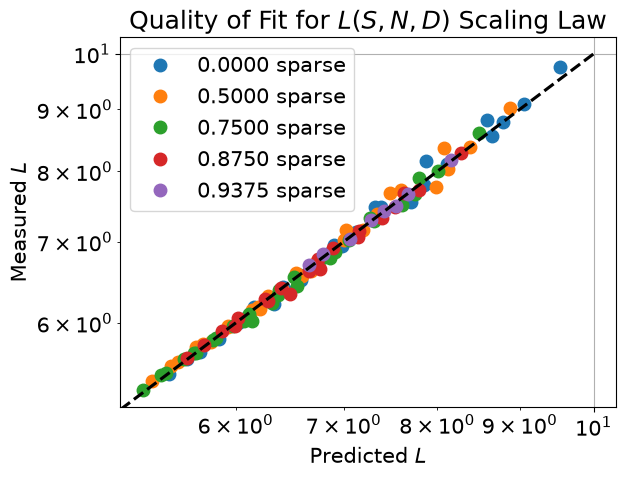

In [5]:
pred = law(x, params)
for sparsity in [0, 0.5, 0.75, 0.875, 1 - 1 / 16]:
  tmp = x[0] == sparsity
  plt.plot(pred[tmp], y[tmp], 'o', label='%.4f sparse' % sparsity)
plt.plot([0, 10], [0, 10], '--', color='black')

plt.xscale('log')
plt.yscale('log')
plt.grid()
plt.xlabel('Predicted $L$')
plt.ylabel('Measured $L$')
plt.legend()
plt.title('Quality of Fit for $L(S, N, D)$ Scaling Law')

plt.show()

# Read T5 data

In [6]:
data = pd.read_csv('t5-data.csv')

PARAM_COUNT = 24 * (12 * 768 ** 2)
S = data['sparsity']
N = PARAM_COUNT * data['scale'] * (1 - data['sparsity'])
N /= 10 ** 6
D = data['steps']
D /= 10 ** 5
L = data['val-loss']

x = np.stack((S, N, D))
y = np.array(L)

# Fit Scaling Coefficients

In [7]:
def huber(f, x, y, delta, log):
  def res(params):
    if log:
      res = np.abs(np.log(f(x, params)) - np.log(y))
    else:
      res = np.abs(f(x, params) - y)
    outlier = res > delta
    loss = np.sum(delta * (res[outlier] - .5 * delta))
    loss += np.sum(.5 * res[~outlier] ** 2)
    return loss / y.size
  return res

def law(x, params):
  S, N, D = x[0], x[1], x[2]
  a, b, c, d, e, f, g = params
  sparse = a * (1 / (1 - S)) ** -b + c
  return sparse * N ** -d + e * D ** -f + g

# Note that we follow the Chinchilla loss function here
loss = lambda f, x, y: huber(f, x, y, 0.001, True)

np.random.seed(1)

best = None
for _ in range(25):
  res = scipy.optimize.minimize(
      loss(law, x, y), np.random.uniform(size=7)
  )
  if res['success']:
    print(res['fun'])
    if best is None or best['fun'] > res['fun']:
      best = res
      print(best['fun'])

print('coefs', best['x'])
print('loss', best['fun'])
params = best['x']

1.1767821507011657e-05
1.1767821507011657e-05
1.0701043838174708e-05
1.0701043838174708e-05
8.428720374818253e-06
8.428720374818253e-06
1.1816067559529174e-05
8.258198559690851e-06
8.258198559690851e-06
8.816214770470136e-06
9.462555786175231e-06
9.38136186204356e-06
1.1277221554096933e-05
1.1478081011251485e-05
1.2478039752303144e-05
9.005476152655503e-06
7.594028636556815e-06
7.594028636556815e-06
1.2298879894399905e-05
8.5627416988208e-06
1.0947200902691534e-05
1.2293269366546264e-05
1.2644547369391976e-05


1.139317568532175e-05
8.296135621954434e-06
1.2045082471177252e-05
1.205803827213454e-05
1.0522179561382072e-05
9.622296391135575e-06
1.1386982851705683e-05
coefs [0.56010372 0.71954011 1.52234246 0.24559    0.63789679 0.20769827
 0.65459296]
loss 7.594028636556815e-06


# Plot Quality of Fit

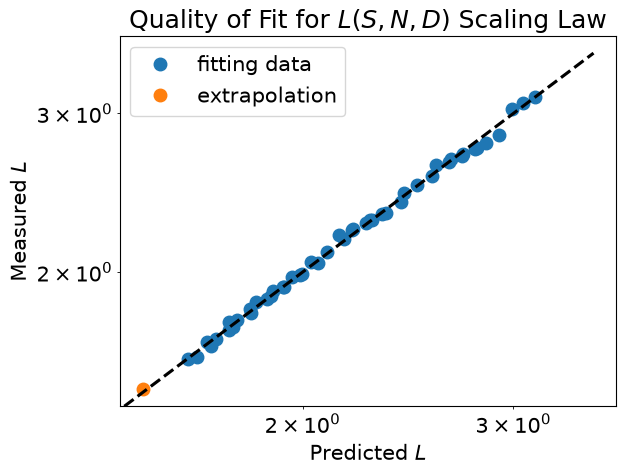

In [8]:
pred = law(x, params)
extrapolation_x = [
    law([0.75, 48 * (12 * 1024 ** 2) / 10 ** 6, 500_000 / 10 ** 5], params),
]
extrapolation_y = 1.4827780204906797
plt.plot(pred, y, 'o', label='fitting data')
plt.plot(extrapolation_x, extrapolation_y, 'o', label='extrapolation')
plt.plot([0, 3.5], [0, 3.5], '--', color='black')

plt.xscale('log')
plt.yscale('log')
plt.grid()
plt.xlabel('Predicted $L$')
plt.ylabel('Measured $L$')
plt.legend()
plt.title('Quality of Fit for $L(S, N, D)$ Scaling Law')

plt.show()